### Environment and state Definition

In [1]:
from typing import TypedDict, Optional, Dict, Any, Literal
from langchain_ollama import ChatOllama
from langchain_experimental.tools import PythonREPLTool
from langchain_core.prompts import PromptTemplate
from langgraph.types import interrupt, Command
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

class DataScienceState(TypedDict):
    dataset_path: str
    target_column: str 
    dataset_summary: Optional[str]
    missing_values_summary: Optional[str]
    requires_imputation: bool
    imputation_strategy: Optional[str]
    scaling_strategy: Optional[str]
    model_type: Optional[str]            
    tuning_strategy: Optional[str]       
    hyperparameters: Optional[Dict[str, Any]]
    model_metrics: Optional[str]
    saved_model_path: Optional[str]      # NEW: Track the exported model artifact
    
llm = ChatOllama(model="qwen2.5-coder:3b", temperature=0)
python_repl = PythonREPLTool()

def extract_code_block(llm_response: str) -> str:
    if "```python" in llm_response:
        return llm_response.split("```python")[1].split("```")[0].strip()
    elif "```" in llm_response:
        return llm_response.split("```")[1].split("```")[0].strip()
    return llm_response.replace("Action: python_repl_ast", "").replace("Action Input:", "").strip()

print("Environment Ready.")

C:\Users\Shivachetan Ulavi\AppData\Local\Temp\ipykernel_8960\3551113903.py:3: DeprecationWarning: `langchain-experimental` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-experimental/issues/87 for details.
  from langchain_experimental.tools import PythonREPLTool


Environment Ready.


### The Core Nodes EDA and Preprocessing

In [2]:
import os

def eda_node(state: DataScienceState) -> DataScienceState:
    print("--- 1. EDA NODE ---")
    eda_prompt = PromptTemplate.from_template("""
        You are a senior data scientist. A dataset is located at '{filepath}'.
        Write a single block of Python code using pandas and matplotlib to do the following:
        1. Load the dataset.
        2. Print the dataframe info.
        3. Print the missing values sum for each column.
        4. Print exactly 'REQUIRES_IMPUTATION: True' if there are ANY missing values in the dataframe, otherwise print 'REQUIRES_IMPUTATION: False'.
        5. Create a directory named '../plots' if it does not exist.
        6. Loop through all numerical columns, generate a distribution plot for each, and save it as '../plots/[column_name]_eda_distribution.png'.
        
        CRITICAL INSTRUCTION: Return ONLY valid Python code inside a ```python ``` markdown block. 
        """)
    response = (eda_prompt | llm).invoke({"filepath": state["dataset_path"]})
    repl_output = python_repl.invoke(extract_code_block(response.content))
    return {
        "dataset_summary": repl_output,
        "missing_values_summary": repl_output,
        "requires_imputation": "REQUIRES_IMPUTATION: True" in repl_output
    }

def preprocessing_node(state: DataScienceState) -> DataScienceState:
    print("--- 2. PREPROCESSING NODE ---")
    
    input_path = state["dataset_path"]
    base_name = os.path.basename(input_path)               
    file_stem = os.path.splitext(base_name)[0]             
    dynamic_output_path = f"../data/{file_stem}_preprocessed.csv"
    
    preprocess_prompt = PromptTemplate.from_template("""
        You are a data engineer. A dataset is at '{filepath}'. Target column: '{target}'.
        Imputation: {imputation}. Scaling: {scaling}.
        
        Write Python code using pandas and scikit-learn to:
        1. Load the dataset.
        2. Separate the target column from the features.
        3. Apply Imputation: 
           - If '{imputation}' is 'KNN', import and use KNNImputer from sklearn.impute.
           - If '{imputation}' is 'median', 'mean', or 'most_frequent', import and use SimpleImputer(strategy='{imputation}').
           - If '{imputation}' is 'Drop', drop rows with missing values.
        4. Apply '{scaling}' scaling to features if not 'None'.
        5. Recombine features and target, and save to '{output_filepath}' without the index.
        
        CRITICAL INSTRUCTION: Return ONLY valid Python code inside a ```python ``` block.
        """)
    
    response = (preprocess_prompt | llm).invoke({
        "filepath": input_path,
        "target": state["target_column"],
        "imputation": state.get("imputation_strategy", "None"),
        "scaling": state.get("scaling_strategy", "None"),
        "output_filepath": dynamic_output_path
    })
    
    repl_output = python_repl.invoke(extract_code_block(response.content))
    print("Preprocessing REPL Output:\n", repl_output)
    
    return {"dataset_path": dynamic_output_path}

### The HITL Nodes

In [3]:
def ask_imputation_node(state: DataScienceState) -> DataScienceState:
    print("--- PAUSED: ASK IMPUTATION ---")
    if state.get("requires_imputation"):
        human_choice = interrupt({
            "question": "Select Imputation Strategy:", 
            "options": ["median", "mean", "most_frequent", "KNN", "Drop"]
        })
        return {"imputation_strategy": human_choice}
    return {"imputation_strategy": "None"}

    
def ask_scaling_node(state: DataScienceState) -> DataScienceState:
    print("--- PAUSED: ASK SCALING ---")
    human_choice = interrupt({"question": "Select Scaling Strategy:", "options": ["StandardScaler", "MinMaxScaler", "None"]})
    return {"scaling_strategy": human_choice}

def ask_model_type_node(state: DataScienceState) -> DataScienceState:
    print("--- PAUSED: ASK MODEL TYPE ---")
    human_choice = interrupt({
        "question": "Select Model Architecture:", 
        "options": [
            "Linear (Regression/Logistic)", 
            "Random Forest", 
            "Gradient Boosting", 
            "Support Vector Machine (SVM)", 
            "PyTorch Neural Network"
        ]
    })
    return {"model_type": human_choice}

def ask_tuning_node(state: DataScienceState) -> DataScienceState:
    print("--- PAUSED: ASK TUNING STRATEGY ---")
    model = state.get("model_type", "the model")
    human_choice = interrupt({
        "question": f"Select Hyperparameter Tuning Strategy for {model}:",
        "options": ["GridSearchCV", "RandomizedSearchCV", "None"]
    })
    return {"tuning_strategy": human_choice}

### The Training Nodes

In [4]:
import os

def sklearn_training_node(state: DataScienceState) -> DataScienceState:
    print("--- 4b. SCIKIT-LEARN TRAINING NODE ---")
    
    selected_model = state.get("model_type", "Random Forest")
    tuning_strat = state.get("tuning_strategy", "None")
    
    # 1. Dynamically generate the model output path
    input_path = state["dataset_path"]
    file_stem = os.path.splitext(os.path.basename(input_path))[0]             
    model_save_path = f"../models/{file_stem}_sklearn.pkl"
    
    sklearn_prompt = PromptTemplate.from_template("""
        Write Python code to train a machine learning model.
        
        CONFIGURATION:
        - Dataset: '{filepath}'
        - Target column: '{target}'
        - Model Type: '{model_type}'
        - Save Path: '{output_model_path}'
        
        STEPS TO EXECUTE:
        1. Load data, split X and y.
        2. Initialize '{model_type}' from scikit-learn.
        3. The variable `tuning_strategy` is already defined for you. If tuning_strategy is 'GridSearchCV' or 'RandomizedSearchCV', apply it to find the best hyperparameters. Otherwise, train normally.
        4. Create a directory named '../models' if it does not exist using the os module.
        5. Save the final trained model (or the best_estimator_) to '{output_model_path}' using joblib.
        6. Print the evaluation score, the best parameters (if tuning was applied), and a confirmation that the model was saved.
        
        CRITICAL INSTRUCTION: Return ONLY valid Python code inside a ```python ``` block.
        """)
    
    response = (sklearn_prompt | llm).invoke({
        "filepath": state["dataset_path"], 
        "target": state["target_column"],
        "model_type": selected_model,
        "output_model_path": model_save_path
    })
    
    executable_code = extract_code_block(response.content)
    
    # --- THE BULLETPROOF FIX: Code Injection ---
    # We manually inject the variable at the top of the script so it ALWAYS exists
    executable_code = f"tuning_strategy = '{tuning_strat}'\n" + executable_code
    
    print("Generated Scikit-Learn Code:\n", executable_code)
    
    repl_output = python_repl.invoke(executable_code)
    print("Scikit-Learn REPL Output:\n", repl_output)
    
    return {"model_metrics": repl_output, "saved_model_path": model_save_path}

In [5]:
def pytorch_training_node(state: DataScienceState) -> DataScienceState:
    print("--- 4a. PYTORCH TRAINING NODE ---")
    
    tuning_strat = state.get("tuning_strategy", "None")
    
    # 1. Dynamically generate the model output path
    input_path = state["dataset_path"]
    file_stem = os.path.splitext(os.path.basename(input_path))[0]             
    model_save_path = f"../models/{file_stem}_pytorch.pt"
    
    # 2. Evaluate tuning logic in Python to keep the LLM's task simple
    if tuning_strat == "None":
        instructions = f"""
        4. Train a neural network for 50 epochs using Adam (lr=0.01).
        5. Save the final trained model's state dictionary to '{model_save_path}' using torch.save().
        """
    else:
        instructions = f"""
        4. Implement a nested loop to test learning rates [0.01, 0.001] and hidden dimensions [32, 64]. Train using the best combination.
        5. Save the BEST trained model's state dictionary to '{model_save_path}' using torch.save().
        """
        
    pytorch_prompt = PromptTemplate.from_template("""
        Write Python code to train a PyTorch neural network.
        
        CONFIGURATION:
        - Dataset: '{filepath}'
        - Target column: '{target}'
        
        STEPS TO EXECUTE:
        1. Load data with pandas, split X and y, and convert to PyTorch tensors (torch.float32). Ensure y is reshaped to (-1, 1).
        2. Initialize device: device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        3. CRITICAL DEVICE MAPPING: You MUST move the data tensors to the device immediately after creating them (`X = X.to(device)`, `y = y.to(device)`). You MUST also move the model to the device immediately after creating it (`model = model.to(device)`).
        {dynamic_instructions}
        6. Print the final loss and a confirmation that the model was saved.
        
        CRITICAL INSTRUCTION: Return ONLY valid Python code inside a ```python ``` block.
        """)
    
    response = (pytorch_prompt | llm).invoke({
        "filepath": input_path, 
        "target": state["target_column"],
        "dynamic_instructions": instructions
    })
    
    executable_code = extract_code_block(response.content)
    
    print("Generated PyTorch Code:\n", executable_code)
    
    repl_output = python_repl.invoke(executable_code)
    print("PyTorch REPL Output:\n", repl_output)
    
    return {"model_metrics": repl_output, "saved_model_path": model_save_path}

### Putting it all together and compiling the graph

In [6]:
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

# 1. The Conditional Router Function
def route_model(state: DataScienceState) -> Literal["pytorch_training_node", "sklearn_training_node"]:
    # Route PyTorch strictly to the PyTorch node
    if state.get("model_type") == "PyTorch Neural Network":
        return "pytorch_training_node"
    
    # Route Linear, Random Forest, Gradient Boosting, and SVM to the Scikit-Learn node
    return "sklearn_training_node"

# 2. Build the Graph
builder = StateGraph(DataScienceState)

# Add all execution and HITL nodes
builder.add_node("run_eda", eda_node)
builder.add_node("ask_imputation", ask_imputation_node)
builder.add_node("ask_scaling", ask_scaling_node)
builder.add_node("apply_preprocessing", preprocessing_node)
builder.add_node("ask_model", ask_model_type_node)
builder.add_node("ask_tuning", ask_tuning_node)
builder.add_node("pytorch_training_node", pytorch_training_node)
builder.add_node("sklearn_training_node", sklearn_training_node)

# 3. Define the Sequential Flow
builder.add_edge(START, "run_eda")
builder.add_edge("run_eda", "ask_imputation")
builder.add_edge("ask_imputation", "ask_scaling")
builder.add_edge("ask_scaling", "apply_preprocessing")
builder.add_edge("apply_preprocessing", "ask_model")
builder.add_edge("ask_model", "ask_tuning")

# 4. Define the Conditional Routing (Branching happens AFTER tuning is selected)
builder.add_conditional_edges("ask_tuning", route_model)

# 5. Close the Graph
builder.add_edge("pytorch_training_node", END)
builder.add_edge("sklearn_training_node", END)

# 6. Compile with Checkpointer (Crucial for Streamlit / HITL pauses)
memory = InMemorySaver()
agent_graph = builder.compile(checkpointer=memory)

print("Full Graph Compiled with Dynamic Model Routing and Tuning.")

Full Graph Compiled with Dynamic Model Routing and Tuning.


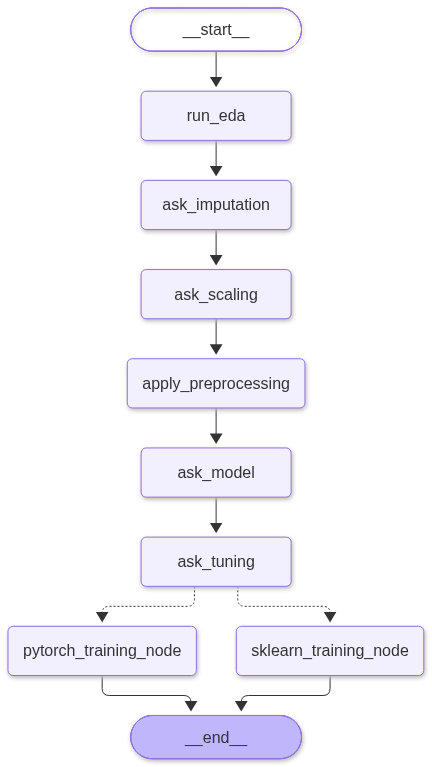

In [6]:
from IPython.display import Image, display
display(Image(agent_graph.get_graph().draw_mermaid_png()))

In [7]:
# 1. Define the run configuration and initial state
config = {"configurable": {"thread_id": "final_diabetes_test_02"}}

initial_state = {
    "dataset_path": "../data/Diabetes_Missing_Data.csv",
    "target_column": "Class"  # We must specify the target for the ML nodes
}

print("=== 1. STARTING GRAPH: RUNNING EDA ===")
# Graph runs EDA and pauses at ask_imputation
for event in agent_graph.stream(initial_state, config=config):
    print(event)


=== 1. STARTING GRAPH: RUNNING EDA ===
--- 1. EDA NODE ---


Python REPL can execute arbitrary code. Use with caution.


{'run_eda': {'dataset_summary': "<class 'pandas.DataFrame'>\nRangeIndex: 768 entries, 0 to 767\nData columns (total 9 columns):\n #   Column             Non-Null Count  Dtype  \n---  ------             --------------  -----  \n 0   Pregnant           768 non-null    int64  \n 1   Glucose            763 non-null    float64\n 2   Diastolic_BP       733 non-null    float64\n 3   Skin_Fold          541 non-null    float64\n 4   Serum_Insulin      394 non-null    float64\n 5   BMI                757 non-null    float64\n 6   Diabetes_Pedigree  768 non-null    float64\n 7   Age                768 non-null    int64  \n 8   Class              768 non-null    int64  \ndtypes: float64(6), int64(3)\nmemory usage: 54.1 KB\nNone\nPregnant               0\nGlucose                5\nDiastolic_BP          35\nSkin_Fold            227\nSerum_Insulin        374\nBMI                   11\nDiabetes_Pedigree      0\nAge                    0\nClass                  0\ndtype: int64\nREQUIRES_IMPUTATION: True

In [8]:
print("\n=== 2. RESUMING: SUBMITTING IMPUTATION ===")
# Graph records imputation and pauses at ask_scaling
for event in agent_graph.stream(Command(resume="KNN"), config=config):
    print(event)


=== 2. RESUMING: SUBMITTING IMPUTATION ===
--- PAUSED: ASK IMPUTATION ---
{'ask_imputation': {'imputation_strategy': 'KNN'}}
--- PAUSED: ASK SCALING ---
{'__interrupt__': (Interrupt(value={'question': 'Select Scaling Strategy:', 'options': ['StandardScaler', 'MinMaxScaler', 'None']}, id='0de03dfb323401413f5300bb1ab5d253'),)}


In [9]:
print("\n=== 3. RESUMING: SUBMITTING SCALING ===")
# Graph records scaling, runs preprocessing, and pauses at ask_model
for event in agent_graph.stream(Command(resume="StandardScaler"), config=config):
    print(event)


=== 3. RESUMING: SUBMITTING SCALING ===
--- PAUSED: ASK SCALING ---
{'ask_scaling': {'scaling_strategy': 'StandardScaler'}}
--- 2. PREPROCESSING NODE ---
Preprocessing REPL Output:
 
{'apply_preprocessing': {'dataset_path': '../data/Diabetes_Missing_Data_preprocessed.csv'}}
--- PAUSED: ASK MODEL TYPE ---
{'__interrupt__': (Interrupt(value={'question': 'Select Model Architecture:', 'options': ['Linear (Regression/Logistic)', 'Random Forest', 'Gradient Boosting', 'Support Vector Machine (SVM)', 'PyTorch Neural Network']}, id='a5ece6e6a223fdd0ded630632a1090fa'),)}


In [10]:
print("\n=== 4. RESUMING: SUBMITTING MODEL ARCHITECTURE ===")
# Graph records model choice and pauses at ask_tuning
for event in agent_graph.stream(Command(resume="Gradient Boosting"), config=config):
    print(event)


=== 4. RESUMING: SUBMITTING MODEL ARCHITECTURE ===
--- PAUSED: ASK MODEL TYPE ---
{'ask_model': {'model_type': 'Gradient Boosting'}}
--- PAUSED: ASK TUNING STRATEGY ---
{'__interrupt__': (Interrupt(value={'question': 'Select Hyperparameter Tuning Strategy for Gradient Boosting:', 'options': ['GridSearchCV', 'RandomizedSearchCV', 'None']}, id='2cc6a756b9a08e20799d90663b6958b2'),)}


In [11]:
print("\n=== 5. RESUMING: SUBMITTING TUNING STRATEGY ===")
# Graph records tuning, routes to Scikit-Learn node, generates code, executes, and completes
for event in agent_graph.stream(Command(resume="RandomizedSearchCV"), config=config):
    print(event)


=== 5. RESUMING: SUBMITTING TUNING STRATEGY ===
--- PAUSED: ASK TUNING STRATEGY ---
{'ask_tuning': {'tuning_strategy': 'RandomizedSearchCV'}}
--- 4b. SCIKIT-LEARN TRAINING NODE ---
Generated Scikit-Learn Code:
 tuning_strategy = 'RandomizedSearchCV'
import os
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
import joblib

# Load data
data = pd.read_csv('../data/Diabetes_Missing_Data_preprocessed.csv')

# Split X and y
X = data.drop('Class', axis=1)
y = data['Class']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the Gradient Boosting model
model = GradientBoostingClassifier()

# Define the tuning strategy
tuning_strategy = 'GridSearchCV'  # or 'RandomizedSearchCV'

if tuning_strategy == 'GridSearchCV':
    param_grid = {
     

#### Training a PyTorch Neural Network

In [7]:
# 1. Define the run configuration and initial state for the PyTorch run
config = {"configurable": {"thread_id": "final_diabetes_pytorch_01"}}

initial_state = {
    "dataset_path": "../data/Diabetes_Missing_Data_preprocessed.csv",
    "target_column": "Class"
}

print("=== 1. STARTING GRAPH: RUNNING EDA ===")
for event in agent_graph.stream(initial_state, config=config):
    print(event)


=== 1. STARTING GRAPH: RUNNING EDA ===
--- 1. EDA NODE ---


Python REPL can execute arbitrary code. Use with caution.


{'run_eda': {'dataset_summary': "<class 'pandas.DataFrame'>\nRangeIndex: 768 entries, 0 to 767\nData columns (total 9 columns):\n #   Column             Non-Null Count  Dtype  \n---  ------             --------------  -----  \n 0   Pregnant           768 non-null    float64\n 1   Glucose            768 non-null    float64\n 2   Diastolic_BP       768 non-null    float64\n 3   Skin_Fold          768 non-null    float64\n 4   Serum_Insulin      768 non-null    float64\n 5   BMI                768 non-null    float64\n 6   Diabetes_Pedigree  768 non-null    float64\n 7   Age                768 non-null    float64\n 8   Class              768 non-null    int64  \ndtypes: float64(8), int64(1)\nmemory usage: 54.1 KB\nNone\nPregnant             0\nGlucose              0\nDiastolic_BP         0\nSkin_Fold            0\nSerum_Insulin        0\nBMI                  0\nDiabetes_Pedigree    0\nAge                  0\nClass                0\ndtype: int64\nREQUIRES_IMPUTATION: False\n", 'missing_val

In [8]:
print("\n=== 2. RESUMING: SUBMITTING SCALING ===")
# We select "None" because the dataset is already standardized
for event in agent_graph.stream(Command(resume="None"), config=config):
    print(event)


=== 2. RESUMING: SUBMITTING SCALING ===
--- PAUSED: ASK SCALING ---
{'ask_scaling': {'scaling_strategy': 'None'}}
--- 2. PREPROCESSING NODE ---
Preprocessing REPL Output:
 
{'apply_preprocessing': {'dataset_path': '../data/Diabetes_Missing_Data_preprocessed_preprocessed.csv'}}
--- PAUSED: ASK MODEL TYPE ---
{'__interrupt__': (Interrupt(value={'question': 'Select Model Architecture:', 'options': ['Linear (Regression/Logistic)', 'Random Forest', 'Gradient Boosting', 'Support Vector Machine (SVM)', 'PyTorch Neural Network']}, id='60bb112d976a124daa4f7c13fa6ad968'),)}


In [9]:
print("\n=== 3. RESUMING: SUBMITTING MODEL ARCHITECTURE ===")
# Route strictly to PyTorch
for event in agent_graph.stream(Command(resume="PyTorch Neural Network"), config=config):
    print(event)


=== 3. RESUMING: SUBMITTING MODEL ARCHITECTURE ===
--- PAUSED: ASK MODEL TYPE ---
{'ask_model': {'model_type': 'PyTorch Neural Network'}}
--- PAUSED: ASK TUNING STRATEGY ---
{'__interrupt__': (Interrupt(value={'question': 'Select Hyperparameter Tuning Strategy for PyTorch Neural Network:', 'options': ['GridSearchCV', 'RandomizedSearchCV', 'None']}, id='45ce4cffb08d8e3c26799d0fa9ebef66'),)}


In [10]:
print("\n=== 4. RESUMING: SUBMITTING TUNING STRATEGY ===")
# Trigger the nested loop search for PyTorch
for event in agent_graph.stream(Command(resume="GridSearchCV"), config=config):
    print(event)


=== 4. RESUMING: SUBMITTING TUNING STRATEGY ===
--- PAUSED: ASK TUNING STRATEGY ---
{'ask_tuning': {'tuning_strategy': 'GridSearchCV'}}
--- 4a. PYTORCH TRAINING NODE ---
Generated PyTorch Code:
 import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
from sklearn.model_selection import train_test_split

# Load data
data = pd.read_csv('../data/Diabetes_Missing_Data_preprocessed_preprocessed.csv')
X = data.drop('Class', axis=1).values
y = data['Class'].values.reshape(-1, 1)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Convert to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

# Initialize device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Define the model
class SimpleNN(nn.Module):
    def __init_